In [1]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle

**Loading in DHS data**

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

(733, 3591898)

In [3]:
data_coo = sp.sparse.coo_matrix(dhs.values)

**Previously trained (80/20 train/test split) model (k=10 components, epochs=30)**

In [18]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model30.pickle', 'rb')
DHS_model30=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data30.pickle', 'rb')
DHS_data30=pickle.load(pickle_in)

In [296]:
rec_info = sample_recommendation(DHS_model30, DHS_data30, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr6:43383800-43384008, Component: Lymphoid, Number of Samples: 229
      chr22:20463632-20463840, Component: Lymphoid, Number of Samples: 77
      chr2:64283739-64283940, Component: Lymphoid, Number of Samples: 74
      chr15:89017645-89017840, Component: Tissue invariant, Number of Samples: 571
      chr1:225467176-225467360, Component: Lymphoid, Number of Samples: 115


In [298]:
comp_precision = []
comp_recall = []
for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
    p, r = component_precision(rec_info[0], 'Lymphoid', k)
    comp_precision.append(p)
    comp_recall.append(r)

Text(0.5, 1.0, 'Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

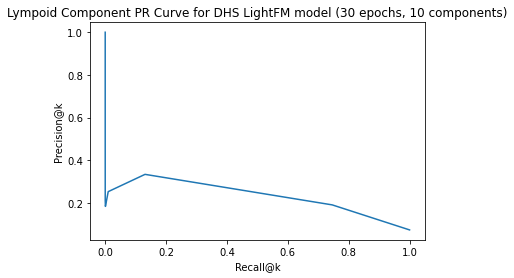

In [299]:
#Lymphoid component pr curve
plt.plot(comp_recall, comp_precision)
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.title('Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

In [35]:
#Precision and Recall @ k scores for DHS_data30.pickle and DHS_model30.pickle
with open('test_precision.txt') as f:
    test_precision = f.readlines()
print(test_precision)
with open('test_recall.txt') as f:
    test_recall = f.readlines()
print(test_recall)

print()
with open('train_precision.txt') as f:
    train_precision = f.readlines()
print(train_precision)
with open('train_recall.txt') as f:
    train_recall = f.readlines()
print(train_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]']
['Test Recall@[1, 10, 100, 1000, 10000] = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]']
['Train Recall@[1, 10, 100, 1000, 10000] = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]']


In [15]:
test_precision = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]
test_recall = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]

train_precision = [0.82673943, 0.8308322, 0.8227558, 0.81127965, 0.7803032]
train_recall = [1.4393877337148873e-05, 0.00014346459243132665, 0.001424563018470999, 0.014067948038458017, 0.13405498314124664]

In [ ]:
#Plot precision-recall curves for train and test data
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (30 epochs, 10 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211004.jpeg')

**Second Model (k=16 components, epochs=15) with Train/Test split of 80/20**

In [38]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test}

In [39]:
#creating model
model_e15_d16 = LightFM(no_components=16, loss='warp')

In [40]:
#training model
model_e15_d16.fit(data['train'], epochs=15, num_threads=2)

In [41]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'wb')
pickle.dump(model_e15_d16, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [33]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16.pickle', 'rb')
DHS_model_e15_d16=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16.pickle', 'rb')
DHS_data_e15_d16=pickle.load(pickle_in)

In [7]:
#Calculating precision and recall for test set
test_precision_list_top = []
test_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(test_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    test_precision_list_top.append(precision)
    test_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.15006821282401092
1.1607047374607913e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1281036834924966
0.00010259687720124615
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.13607094133697137
0.0010623306048059748
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1459781718963165
0.011175172057686316
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.1600350613915416
0.11879437216194183


In [8]:
#Calculating precision and recall for train set
train_precision_list_top = []
train_recall_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    n_known_pos = []
    for biosample in range(733):
        if biosample % 100 == 0:
            print(biosample, '/', n_biosamples)
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
        n_known_pos.append(len(known_pos))
            
    num = np.array(num)
    precision = (num/k).mean()
    recall = (num/n_known_pos).mean()
    print(precision)
    print(recall)
    train_precision_list_top.append(precision)
    train_recall_list_top.append(recall)

1
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8362892223738063
1.4589387054741919e-05
10
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8575716234652115
0.000148460313560959
100
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8448158253751705
0.0014616834782521981
1000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.8309222373806274
0.014391052828586376
10000
0 / 733
100 / 733
200 / 733
300 / 733
400 / 733
500 / 733
600 / 733
700 / 733
0.7954879945429739
0.13631831128367736


In [9]:
model_e15_d16_test_precision = [0.15006821282401092, 0.1281036834924966, 0.13607094133697137, 0.1459781718963165, 0.1600350613915416]
model_e15_d16_test_recall = [1.1607047374607913e-05, 0.00010259687720124615, 0.0010623306048059748, 0.011175172057686316, 0.11879437216194183]

model_e15_d16_train_precision = [0.8362892223738063, 0.8575716234652115, 0.8448158253751705, 0.8309222373806274, 0.7954879945429739]
model_e15_d16_train_recall = [1.4589387054741919e-05, 0.000148460313560959, 0.0014616834782521981, 0.014391052828586376, 0.13631831128367736]

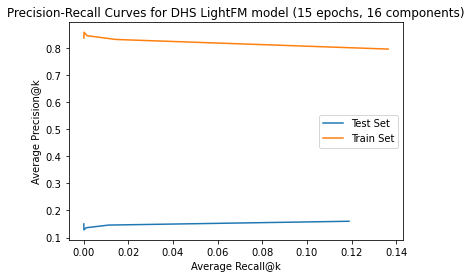

In [18]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(test_recall_list_top, test_precision_list_top)
plt.plot(train_recall_list_top, train_precision_list_top)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set']) #, 'Train Set'
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')
plt.savefig('PR_Curves_DHS_LightFM_CT20211005.jpeg')

In [ ]:
sample_recommendation(DHS_model_e15_d16, DHS_data_e15_d16, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr10:41860220-41860380, Component: Tissue invariant, Number of Samples: 726
      chr20:50958700-50958900, Component: Tissue invariant, Number of Samples: 644
      chr6:30556860-30557080, Component: Tissue invariant, Number of Samples: 683
      chr1:86915341-86915607, Component: Tissue invariant, Number of Samples: 311
      chr16:34582143-34582318, Component: Tissue invariant, Number of Samples: 713

Number of known positive recs before 5 new recs: 143


**Creating a simple model (with k=1 components and epochs=1) and training the model on 80/20 train/test split**

In [20]:
#creating simple model
model_e1_d1 = LightFM(no_components=1, loss='warp')

In [21]:
#training simple model
model_e1_d1.fit(data['train'], epochs=1, num_threads=2)

In [46]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e1_d1.pickle', 'wb')
pickle.dump(model_e1_d1, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e1_d1.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [35]:
sample_recommendation(model_e1_d1, data, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr3:16601580-16601800, Component: Neural, Number of Samples: 2
      chr10:28432440-28432502, Component: Tissue invariant, Number of Samples: 1
      chr15:30626380-30626560, Component: Stromal B, Number of Samples: 277
      chr17:61839568-61839657, Component: Pulmonary devel., Number of Samples: 1
      chr3:52288517-52288726, Component: Placental / trophoblast, Number of Samples: 4

Number of known positive recs before 5 new recs: 75


In [38]:
train_dense = data['train'].todense()
test_dense = data['test'].todense()

In [43]:
#Making sure the external precision recall function I wrote (see precision_recall_function_DHS_test_CT20211005.py)
#matches the function written in this notebook
test_precision_e1_d1, test_recall_e1_d1 = precision_recall(test_dense, model_e1_d1)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.1937244201909959
recall@1 = 1.3154694509024866e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.19276944065484314
recall@10 = 0.0001351832908074869
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.19395634379263305
recall@100 = 0.0013733302147636588
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamp

In [53]:
#Precision and Recall @ k scores for DHS_moodel_e1_d1 obtained from precision_recall_function_DHS_test_CT20211005.py
with open('DHS_model_e1_d1_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
with open('DHS_model_e1_d1_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.1937244201909959, 0.19276944065484314, 0.19395634379263305, 0.18997407912687586, 0.1798338335607094] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [1.3154694509024866e-05, 0.0001351832908074869, 0.0013733302147636588, 0.013248996263552942, 0.12206706241599925]']
['Train Precision@[1, 10, 100, 1000, 10000] = [0.7830832196452933, 0.7879945429740791, 0.7856616643929059, 0.7712223738062757, 0.7233263301500683] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [1.389557222091376e-05, 0.00013873996087605507, 0.0013754109708364738, 0.013403138149935887, 0.12262116386584553]']


In [54]:
model_e1_d1_test_precision = [0.1937244201909959, 0.19276944065484314, 0.19395634379263305, 0.18997407912687586, 0.1798338335607094]
model_e1_d1_test_recall = [1.3154694509024866e-05, 0.0001351832908074869, 0.0013733302147636588, 0.013248996263552942, 0.12206706241599925]

model_e1_d1_train_precision = [0.7830832196452933, 0.7879945429740791, 0.7856616643929059, 0.7712223738062757, 0.7233263301500683]
model_e1_d1_train_recall = [1.389557222091376e-05, 0.00013873996087605507, 0.0013754109708364738, 0.013403138149935887, 0.12262116386584553]

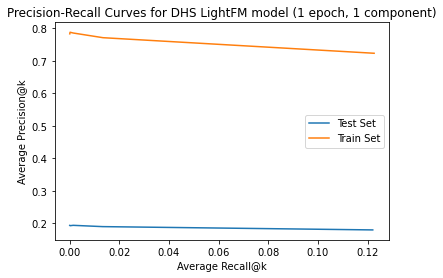

In [56]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(model_e1_d1_test_recall, model_e1_d1_test_precision)
plt.plot(model_e1_d1_train_recall, model_e1_d1_train_precision)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set', 'Train Set'])
plt.title('Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')
plt.savefig('PR_Curves_DHS_model_e1_d1_LightFM_CT20211005.jpeg')

**Training k=1 component, epochs=1 model on 50/50 train/test split data and comparing to same model trained on 80/20 train/test split data**

In [59]:
#50/50 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.5, random_state=None)
data_50_50 = {'train': train, 'test': test}

In [60]:
#creating model
model_e1_d1_tts50 = LightFM(no_components=1, loss='warp')
#training model
model_e1_d1_tts50.fit(data_50_50['train'], epochs=1, num_threads=2)

In [61]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e1_d1_tts50.pickle', 'wb')
pickle.dump(model_e1_d1_tts50, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e1_d1_tts50.pickle', 'wb')
pickle.dump(data_50_50, pickle_out_data)
pickle_out_data.close()

In [63]:
#Precision and Recall @ k scores for DHS_moodel_e1_d1
with open('DHS_model_e1_d1_tts50_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e1_d1_tts50_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.4147339699863574, 0.46439290586630283, 0.4684720327421555, 0.46423874488403827, 0.43699072305593445] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [1.1213092077233432e-05, 0.0001286555667116926, 0.0013036450610856877, 0.012825850763550774, 0.11754179273357541]']

['Train Precision@[1, 10, 100, 1000, 10000] = [0.4965893587994543, 0.49863574351978174, 0.48964529331514334, 0.4750723055934516, 0.4418092769440655] \n', 'Train Recall@[1, 10, 100, 1000, 10000] = [1.3757628389097575e-05, 0.0001397973858022772, 0.0013618001676355498, 0.013083964610770561, 0.11877394989436554]']


In [64]:
model_e1_d1_tts50_test_precision = [0.4147339699863574, 0.46439290586630283, 0.4684720327421555, 0.46423874488403827, 0.43699072305593445]
model_e1_d1_tts50_test_recall = [1.1213092077233432e-05, 0.0001286555667116926, 0.0013036450610856877, 0.012825850763550774, 0.11754179273357541]

model_e1_d1_tts50_train_precision = [0.4965893587994543, 0.49863574351978174, 0.48964529331514334, 0.4750723055934516, 0.4418092769440655]
model_e1_d1_tts50_train_recall = [1.3757628389097575e-05, 0.0001397973858022772, 0.0013618001676355498, 0.013083964610770561, 0.11877394989436554]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')

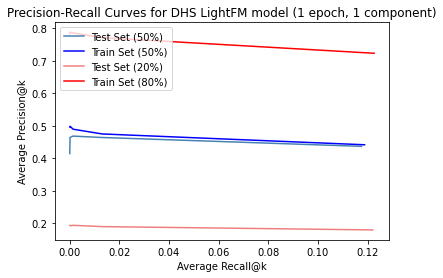

In [79]:
#Plot precision-recall curves for train and test data (1 epochs, 1 dimensions)
plt.plot(model_e1_d1_tts50_test_recall, model_e1_d1_tts50_test_precision, color='steelblue')
plt.plot(model_e1_d1_tts50_train_recall, model_e1_d1_tts50_train_precision, color='blue')
plt.plot(model_e1_d1_test_recall, model_e1_d1_test_precision, color='lightcoral')
plt.plot(model_e1_d1_train_recall, model_e1_d1_train_precision, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (50%)', 'Train Set (50%)', 'Test Set (20%)', 'Train Set (80%)'], 
           loc='upper left')
plt.title('Precision-Recall Curves for DHS LightFM model (1 epoch, 1 component)')
# plt.savefig('PR_Curves_DHS_model_e1_d1_LightFM_CT20211005.jpeg')

**Training k=16 components, epochs=15 model with 50/50 train/test split**

In [100]:
#creating model with 50/50 tts 
model_e15_d16_tts50 = LightFM(no_components=16, loss='warp')
#training model
model_e15_d16_tts50.fit(data_50_50['train'], epochs=15, num_threads=2)

In [101]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_tts50.pickle', 'wb')
pickle.dump(model_e15_d16_tts50, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_tts50.pickle', 'wb')
pickle.dump(data_50_50, pickle_out_data)
pickle_out_data.close()

In [ ]:
#Precision and Recall @ k scores for DHS_model_e15_d16_tts50
with open('DHS_model_e15_d16_tts50_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e15_d16_tts50_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

 **Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.05**

In [104]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.05, k=16 components
model_e15_d16_reg05 = LightFM(no_components=16, loss='warp', item_alpha=0.05, user_alpha=0.05)
#training model
model_e15_d16_reg05.fit(data_80_20['train'], epochs=15, num_threads=2)

In [105]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg05.pickle', 'wb')
pickle.dump(model_e15_d16_reg05, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg05.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

**Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.0001**

In [218]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.0001, k=16 components
model_e15_d16_reg0001 = LightFM(no_components=16, loss='warp', item_alpha=0.0001, user_alpha=0.0001)
#training model
model_e15_d16_reg0001.fit(data_80_20['train'], epochs=15, num_threads=2)

In [307]:
user_b, user_e = model_e15_d16_reg0001.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg0001.get_item_representations()
print(item_e)

[[-2.1138025e-09 -4.0272871e-10  4.1239581e-09 ...  1.2668850e-09
  -2.3141626e-09  3.3952958e-09]
 [-6.3887495e-10  6.4651734e-10  4.3743409e-09 ...  1.4237002e-09
  -3.1071963e-09  1.5738004e-09]
 [-1.6628866e-10 -7.7863282e-10  6.7797972e-09 ...  2.5838838e-09
  -2.4571485e-09  3.4877945e-09]
 ...
 [-4.0140207e-09  1.0742750e-09  2.7537492e-09 ...  2.0706259e-09
  -3.3659839e-09  5.8992269e-09]
 [ 1.7842416e-09  8.3465274e-10  2.8063452e-09 ...  2.6176254e-09
  -1.6286791e-09  3.1994525e-09]
 [-1.6246697e-09 -1.0967471e-09  6.7373005e-09 ...  9.4678676e-10
  -7.4429479e-10  2.6495692e-09]]
[[-9.9547406e-06  3.6766326e-06 -3.7320319e-06 ...  1.0117600e-05
   3.4408713e-06  2.2264298e-06]
 [-8.4824760e-06 -1.0405109e-05 -1.8103501e-05 ... -6.3034358e-06
  -2.8507559e-06 -2.6116049e-06]
 [ 1.9217687e-05  1.2645242e-05 -1.8339260e-05 ...  1.2292383e-05
   5.7014172e-06  1.5635042e-05]
 ...
 [-3.4699567e-06  1.6625163e-06  1.5026339e-06 ...  1.4540527e-06
   1.6540397e-06  3.3531322e-07]

In [220]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'wb')
pickle.dump(model_e15_d16_reg0001, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [4]:
pickle_in = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001.pickle', 'rb')
model_e15_d16_reg0001=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001.pickle', 'rb')
data_e15_d16_reg0001=pickle.load(pickle_in)

In [7]:
data_e15_d16_reg0001['test'].shape

(733, 3591898)

In [221]:
test_dense_e15_d16_reg0001 = data_80_20['test'].todense()
train_dense_e15_d16_reg0001 = data_80_20['train'].todense()

In [222]:
test_precision_e15_d16_reg0001, test_recall_e15_d16_reg0001 = precision_recall(test_dense_e15_d16_reg0001, model_e15_d16_reg0001)
train_precision_e15_d16_reg0001, train_recall_e15_d16_reg0001 = precision_recall(train_dense_e15_d16_reg0001, model_e15_d16_reg0001)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.18144611186903137
recall@1 = 1.3129730370739348e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.17817189631650754
recall@10 = 0.00012456782416461268
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.17937244201909958
recall@100 = 0.0012690288152385329
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosa

In [5]:
test_precision_e15_d16_reg0001 = [0.18144611186903137, 0.17817189631650754, 0.17937244201909958, 0.1859345156889495, 0.1897316507503411]
test_recall_e15_d16_reg0001 = [1.3129730370739348e-05, 0.00012456782416461268, 0.0012690288152385329, 0.01318230492197544, 0.1316735431415578]

train_precision_e15_d16_reg0001 = [0.8171896316507503, 0.8193724420190996, 0.8146111869031378, 0.8051582537517054, 0.7670870395634379]
train_recall_e15_d16_reg0001 = [1.4441680102687852e-05, 0.00014598124450872365, 0.0014411915297099748, 0.014209795101136687, 0.13303056610257932]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

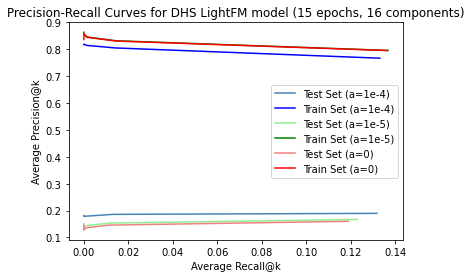

In [10]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(test_recall_e15_d16_reg0001, test_precision_e15_d16_reg0001, color='steelblue')
plt.plot(train_recall_e15_d16_reg0001, train_precision_e15_d16_reg0001, color='blue')
plt.plot(model_e15_d16_reg00001_test_recall, model_e15_d16_reg00001_test_precision, color='lightgreen')
plt.plot(model_e15_d16_reg00001_train_recall, model_e15_d16_reg00001_train_precision, color='green')
plt.plot(model_e15_d16_test_recall, model_e15_d16_test_precision, color='lightcoral')
plt.plot(model_e15_d16_train_recall, model_e15_d16_train_precision, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=1e-4)', 'Train Set (a=1e-4)', 'Test Set (a=1e-5)', 'Train Set (a=1e-5)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

In [306]:
rec_info = sample_recommendation(model_e15_d16_reg0001, data_e15_d16_reg0001, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr19:10251779-10252000, Component: Tissue invariant, Number of Samples: 719
      chr11:72112260-72112520, Component: Tissue invariant, Number of Samples: 717
      chr3:38164980-38165260, Component: Tissue invariant, Number of Samples: 724
      chr19:37779520-37779725, Component: Tissue invariant, Number of Samples: 725
      chr4:94207500-94207700, Component: Tissue invariant, Number of Samples: 715


In [303]:
comp_precision = []
comp_recall = []
for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
    p, r = component_precision(rec_info[0], 'Tissue invariant', k)
    comp_precision.append(p)
    comp_recall.append(r)

Text(0.5, 1.0, 'Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

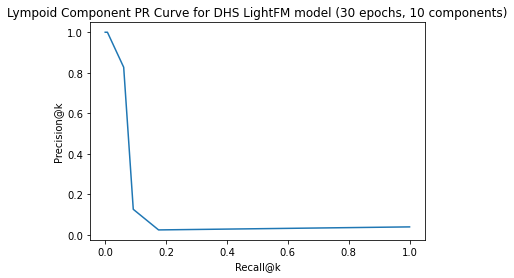

In [304]:
#Lymphoid component pr curve
plt.plot(comp_recall, comp_precision)
plt.xlabel('Recall@k')
plt.ylabel('Precision@k')
plt.title('Lympoid Component PR Curve for DHS LightFM model (30 epochs, 10 components)')

**Adjusting learning rate for model 2 (k=16 components, epochs=15 a=0.0001) to 0.01**

In [4]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.0001, k=16 components, learning rate of 0.01
model_e15_d16_reg0001_lr01 = LightFM(no_components=16, loss='warp', item_alpha=0.0001, user_alpha=0.0001, learning_rate=0.01)
#training model
model_e15_d16_reg0001_lr01.fit(data_80_20['train'], epochs=15, num_threads=2)

In [5]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg0001_lr01.pickle', 'wb')
pickle.dump(model_e15_d16_reg0001_lr01, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg0001_lr01.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

**Adjusting alpha regularization values for model 2 (k=16 components, epochs=15) to 0.00001**

In [111]:
#80/20 train test split to test precision values between train and test datasets
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data_80_20 = {'train': train, 'test': test}
#creating model with L2 regularization set to 0.001, k=16 components
model_e15_d16_reg00001 = LightFM(no_components=16, loss='warp', item_alpha=0.00001, user_alpha=0.00001)
#training model
model_e15_d16_reg00001.fit(data_80_20['train'], epochs=15, num_threads=2)

In [217]:
user_b, user_e = model_e15_d16_reg00001.get_user_representations()
print(user_e)
item_b, item_e = model_e15_d16_reg00001.get_item_representations()
print(item_e)

[[-2.0906634   1.8546653   1.9692941  ... -1.3520951   0.20131573
   0.8666315 ]
 [ 0.6466236   2.066677   -1.0889381  ...  2.4525106   1.3928869
  -0.01660642]
 [-1.9957765   1.4628907   1.2792798  ... -0.02385798  0.07691262
  -0.50173795]
 ...
 [ 1.1927788   3.1767805   0.68129855 ...  0.36804384  2.7848048
   0.21285807]
 [ 0.9045258   2.857363   -0.08097604 ...  0.10201646  5.2988853
  -0.07790955]
 [ 1.0142272   2.9209576  -0.08180873 ...  0.0838751   5.315526
  -0.19112782]]
[[ 0.03318062  0.08973543  0.17065954 ... -0.16512406  0.03641047
  -0.17259715]
 [ 0.15537748  0.04823514 -0.00691903 ... -0.00175932 -0.06660224
  -0.14679715]
 [-0.0933437  -0.08303365  0.13252145 ... -0.06879919 -0.1888858
   0.01975318]
 ...
 [ 0.12554476  0.07025028 -0.07974731 ... -0.00253858  0.02790248
   0.02964003]
 [ 0.15781777  0.07370334  0.09394893 ... -0.23880535 -0.07770683
   0.0022407 ]
 [ 0.08032778  0.0621774   0.10817247 ... -0.21860011 -0.11208315
  -0.03975179]]


In [115]:
pickle_out_model = open('/home/ctrader/Hold/DHS/DHS_model_e15_d16_reg00001.pickle', 'wb')
pickle.dump(model_e15_d16_reg00001, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('/home/ctrader/Hold/DHS/DHS_data_e15_d16_reg00001.pickle', 'wb')
pickle.dump(data_80_20, pickle_out_data)
pickle_out_data.close()

In [211]:
#Precision and Recall @ k scores for DHS_model_e15_d16_reg00001
with open('DHS_model_e15_d16_reg05_test_precision_recall.txt') as f:
    test_precision_recall = f.readlines()
print(test_precision_recall)
print()
with open('DHS_model_e15_d16_reg05_train_precision_recall.txt') as f:
    train_precision_recall = f.readlines()
print(train_precision_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.0, 0.0, 0.0004229195088676672, 0.0031596180081855394, 0.0403237380627558] \n', 'Test Recall@[1, 10, 100, 1000, 10000] = [0.0, 0.0, 1.252601081375641e-06, 0.00011743335744602837, 0.022337723366463093]']



FileNotFoundError: [Errno 2] No such file or directory: 'DHS_model_e15_d16_reg05_train_precision_recall.txt'

In [8]:
model_e15_d16_reg00001_test_precision = [0.1296043656207367, 0.13956343792633016, 0.1440518417462483, 0.15345702592087312, 0.16702046384720326]
model_e15_d16_reg00001_test_recall = [1.1073560697469647e-05, 0.00011351273372921383, 0.0011142584926762563, 0.011633033740440326, 0.12287782314369584]

model_e15_d16_reg00001_train_precision = [0.8635743519781719, 0.8536152796725786, 0.8460163710777626, 0.8318854024556616, 0.7959781718963165]
model_e15_d16_reg00001_train_recall = [1.4809866515884741e-05, 0.0001475213145611531, 0.0014715323307665357, 0.014467299278161039, 0.13673375677728258]

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

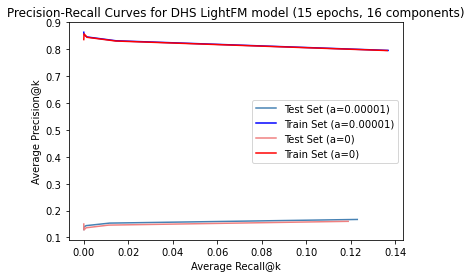

In [226]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
plt.plot(model_e15_d16_reg00001_test_recall, model_e15_d16_reg00001_test_precision, color='steelblue')
plt.plot(model_e15_d16_reg00001_train_recall, model_e15_d16_reg00001_train_precision, color='blue')
plt.plot(test_recall_list_top, test_precision_list_top, color='lightcoral')
plt.plot(train_recall_list_top, train_precision_list_top, color='red')
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set (a=0.00001)', 'Train Set (a=0.00001)', 'Test Set (a=0)', 'Train Set (a=0)'], 
           loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (15 epochs, 16 components)')

**Function to recommend DHSs for a given biosample**

In [8]:
tsv_file = open("DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
# print(df.head(20))

In [9]:
biosample_df = df[['library order', 'Biosample name']]

In [10]:
# print(biosample_df[biosample_df['library order']==1]['Biosample name'][0])
# print(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'][0])

In [11]:
DHS_metadata = pd.read_table('DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [12]:
DHS_metadata.head()

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
2,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
3,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
4,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
5,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast


In [193]:
#chr6:43383800-43384008
seq_mask = DHS_metadata['seqname']=='chr6'
start_mask = DHS_metadata['start']==43383800
end_mask = DHS_metadata['end']==43384008
DHS_metadata[seq_mask & start_mask & end_mask]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
2802885,chr6,43383800,43384008,6.328575,5.0035,229,43383910,43383870.0,43383970.0,Lymphoid


In [194]:
DHS_metadata.iloc[2802885-1]


0
seqname              chr6
start            43383800
end              43384008
identifier       6.328575
mean_signal        5.0035
numsamples            229
summit           43383910
core_start     43383870.0
core_end       43383970.0
component        Lymphoid
Name: 2802885, dtype: object

In [119]:
biosample = list(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'])[0] - 1
print(biosample)

0


In [12]:
x = dhs.T[0]
# x
type(x)

pandas.core.series.Series

In [98]:
comp_list = DHS_metadata.reset_index()
comp_list = comp_list['component']

comp_list[i_access]

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
2,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
3,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
4,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
5,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast
...,...,...,...,...,...,...,...,...,...,...
3591894,chrY,56882540,56882719,Y.994281,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid
3591895,chrY,56882864,56882980,Y.994286,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid
3591896,chrY,56883733,56883960,Y.994292,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast
3591897,chrY,56884440,56884580,Y.994297,0.053759,1,56884510,56884510.0,56884510.0,Lymphoid


In [269]:
DHS_metadata

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
1,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
2,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
3,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
4,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
5,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast
...,...,...,...,...,...,...,...,...,...,...
3591894,chrY,56882540,56882719,Y.994281,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid
3591895,chrY,56882864,56882980,Y.994286,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid
3591896,chrY,56883733,56883960,Y.994292,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast
3591897,chrY,56884440,56884580,Y.994297,0.053759,1,56884510,56884510.0,56884510.0,Lymphoid


In [275]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, biosamples, print_num=3): #, full_data=gd_coo
    
    #number of biosamples and DHSs in dataset
    n_biosamples, n_DHSs = data['train'].shape
    return_list = []
    #generate DHS recommendations for each biosample
    for biosample_name in biosamples:
        biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
        
        #DHSs known to relate to the biosample
        #indices
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
#         print(known_positives.index(737810))
        
        #filter out known positives from what will be recommended
        not_known_ind = list(set(np.arange(n_DHSs)) - set(known_positives))
        nki_series = pd.Series(not_known_ind)
        
        #DHSs model predicts that relate to biosample
#         scores = model.predict(biosample, np.arange(n_DHSs))
        filtered_scores = model.predict(biosample, np.array(not_known_ind))

        #rank from most related to least
#         top_DHSs = [np.argsort(-scores)][0]
        #not DHS indices
        filtered_top_DHSs = [np.argsort(-filtered_scores)][0]
        top_rec_DHSs = nki_series[filtered_top_DHSs]
#         print()
#         print(list(top_DHSs).index(2802884))
#         filtered_DHSs = [dhs_ind for dhs_ind in top_DHSs if dhs_ind not in set(known_positives)]
#         filtered_DHSs = set(top_DHSs)-set(known_positives)
        metadata = DHS_metadata.reset_index()
        comp_ser = metadata['component']
        comp_rec = list(comp_ser[top_rec_DHSs])
#         print(comp_rec[0:5])
        chrom_ser = metadata['seqname']
        chrom_rec = list(chrom_ser[top_rec_DHSs])
        start_ser = metadata['start']
        start_rec = list(start_ser[top_rec_DHSs])
        end_ser = metadata['end']
        end_rec = list(end_ser[top_rec_DHSs])
        numsamples_ser = metadata['numsamples']
        numsamples_rec = list(numsamples_ser[top_rec_DHSs])
        
        
        
        #print results
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        print('   Number of Known DHSs: %s' %(len(known_positives)))
        
        print()
        print('   Recommended DHS Locations:')
        count = 0
        total_count = 0
        return_biosample = []
        return_biosample.append(comp_rec)
        return_biosample.append(chrom_rec)
        return_biosample.append(start_rec)
        return_biosample.append(end_rec)
        return_biosample.append(numsamples_rec)
        return_list.append(return_biosample)
#         coord_list = []
#         comp_list = []
#         sample_num_list = []
        
        for i in range(print_num):
#             DHS = not_known_ind[filtered_DHS]
#             total_count+=1
#             if DHS not in known_positives:
#             DHS_metadata_num = DHS #+1
            chrom = chrom_rec[i]
            start = start_rec[i]
            end = end_rec[i]
            component = comp_rec[i]
            num_samples = numsamples_rec[i]
#             num_samples = DHS_metadata.iloc[DHS_metadata_num]['numsamples']
#             if count < print_num:
            print('      %s:%s-%s, Component: %s, Number of Samples: %s' %(chrom, start, end, component, num_samples))
#             count += 1
#             coord_list.append(str(chrom)+':'+str(start)+'-'+str(end))
#             comp_list.append(component)
#             sample_num_list.append(num_samples)
#             if count == recommend_num:
        
                
#         print()
#         print('Number of known positive recs before %s new recs: %s' %(recommend_num, total_count))
        return return_list

In [289]:
rec_info = sample_recommendation(model_e15_d16_reg0001, data_e15_d16_reg0001, ['GM06990'], print_num=5)

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr19:10251779-10252000, Component: Tissue invariant, Number of Samples: 719
      chr11:72112260-72112520, Component: Tissue invariant, Number of Samples: 717
      chr3:38164980-38165260, Component: Tissue invariant, Number of Samples: 724
      chr19:37779520-37779725, Component: Tissue invariant, Number of Samples: 725
      chr4:94207500-94207700, Component: Tissue invariant, Number of Samples: 715


In [283]:
rec_info[0][4][0:5]

[229, 77, 74, 571, 115]

In [292]:
for k in [1, 10, 100, 1000, 10000, 100000, 1000000, len(rec_info[0][0])]:
    print(component_precision(rec_info[0], 'Lymphoid', k))

254762
(0.0, 0.0)
254762
(0.0, 0.0)
254762
(0.0, 0.0)
254762
(0.0, 0.0)
254762
(0.0083, 0.00032579427073111376)
254762
(0.01737, 0.006818128292288489)
254762
(0.039386, 0.15459919454235718)
254762
(0.07260286465012625, 1.0)
3508980


**Function to calculate component precision values**

In [295]:
#takes in recommendation info for a single biosample and the component to calculate precision values for.
#Returns precision values for this component
def component_precision(rec_info, target_comp, k=1):
    comps = rec_info[0]
    total_of_comp = comps.count(target_comp)
    count = comps[0:k].count(target_comp)
    precision = count/k
    recall = count/total_of_comp
    return precision, recall

**Created function to calculate precision and recall for train and test datasets**

In [42]:
#Function for calculating precision and recall
def precision_recall(dense, model, k_vals=[1, 10, 100, 1000, 10000]):
    precision_list_top = []
    recall_list_top = []
    for k in k_vals:
        print('k = ' + str(k))
        num = []
        n_known_pos = []
        for biosample in range(733):
            if biosample % 100 == 0:
                print(biosample, '/', n_biosamples, 'biosamples done')
            scores = model.predict(biosample, np.arange(n_dhs)) 
            top_DHSs = [np.argsort(-scores)][0][0:k]
            known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(dense[biosample]))) if dhs_pos == 1]
            top_in_known = len([i for i in known_pos if i in top_DHSs])
            num.append(top_in_known)
            n_known_pos.append(len(known_pos))
            
        num = np.array(num)
        precision = (num/k).mean()
        recall = (num/n_known_pos).mean()
        print('precision@%s = %s' %(k, precision))
        print('recall@%s = %s' %(k, recall))
        precision_list_top.append(precision)
        recall_list_top.append(recall)
    return precision_list_top, recall_list_top

**Ensuring that the precision-recall function created matches the precision/recall@k functions created by LightFM**

In [48]:
#makes sure the function works correctly
test_dense30 = DHS_data30['test'].todense()
test_precision_e30_d10, test_recall_e30_d10 = precision_recall(test_dense30, DHS_model30)

k = 1
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@1 = 0.1432469304229195
recall@1 = 1.0259158846487058e-05
k = 10
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@10 = 0.1421555252387449
recall@10 = 0.00010940640060583263
k = 100
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosamples done
600 / 733 biosamples done
700 / 733 biosamples done
precision@100 = 0.1471487039563438
recall@100 = 0.001110413940486401
k = 1000
0 / 733 biosamples done
100 / 733 biosamples done
200 / 733 biosamples done
300 / 733 biosamples done
400 / 733 biosamples done
500 / 733 biosample

**Checking precision values when sampling random DHSs**

In [18]:
#Precision for random recs
from random import sample
precision_list = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    for biosample in range(733):
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(train_dense[biosample]))) if dhs_pos == 1]
        rand_list = sample(range(0, n_dhs), k)
        rand_in_known = len([i for i in known_pos if i in rand_list])
        num.append(rand_in_known)
            
    num = np.array(num)
    precision = (num/k).mean()
    print(precision)
    precision_list.append(precision)

1


KeyboardInterrupt: 

In [ ]:
# measure precision/recall @ k for k=1:50
# test_precision = []
# test_recall = []
# train_precision = []
# train_recall = []

# for i in [1, 10, 100, 1000, 10000]:
#     test_precision.append(precision_at_k(model30_d1, data['test'], k=i).mean())
#     print('i')
#     test_recall.append(recall_at_k(model30, data['test'], k=i).mean())
#     train_precision.append(precision_at_k(model30, data['train'], k=i).mean())
#     train_recall.append(recall_at_k(model30, data['train'], k=i).mean())
#     print("k=" + i + " Finished")